## Introduction

This code is based on the code of Spatial Thoughts (please see references).

However, for the DEM the pystac catalog is used and more specifically the "cop-glo-dem_30" is used for elevation data.

In [ ]:
!pip install pystac-client planetary-computer rioxarray --quiet

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import pandas as pd
import planetary_computer
import rioxarray as rxr

from pystac_client import Client
from rioxarray.merge import merge_arrays

In [ ]:
!wget https://raw.githubusercontent.com/datameet/maps/master/Districts/Census_2011/2011_Dist.dbf
!wget https://raw.githubusercontent.com/datameet/maps/master/Districts/Census_2011/2011_Dist.prj
!wget https://raw.githubusercontent.com/datameet/maps/master/Districts/Census_2011/2011_Dist.shp
!wget https://raw.githubusercontent.com/datameet/maps/master/Districts/Census_2011/2011_Dist.shx

--2026-11-02 09:41:29--  https://raw.githubusercontent.com/datameet/maps/master/Districts/Census_2011/2011_Dist.dbf
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 54678 (53K) [application/octet-stream]
Saving to: ‘2011_Dist.dbf’

2011_Dist.dbf       100%[===================>]  53.40K  --.-KB/s    in 0.04s   

2026-11-02 09:41:29 (1.25 MB/s) - ‘2011_Dist.dbf’ saved [54678/54678]

--2026-11-02 09:41:29--  https://raw.githubusercontent.com/datameet/maps/master/Districts/Census_2011/2011_Dist.prj
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.110.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 

In [ ]:
gdf = gpd.read_file('/content/2011_Dist.shp')

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

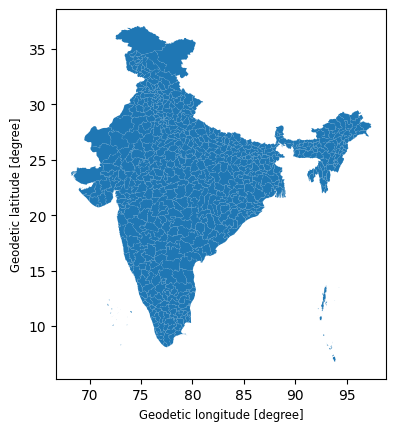

In [ ]:
gdf.plot()

In [ ]:
gdf.head()

,DISTRICT,ST_NM,ST_CEN_CD,DT_CEN_CD,censuscode,geometry
0,Adilabad,Andhra Pradesh,28,1,532,"POLYGON ((78.84972 19.7601, 78.85102 19.75945,..."
1,Agra,Uttar Pradesh,9,15,146,"POLYGON ((78.19803 27.4028, 78.19804 27.40278,..."
2,Ahmadabad,Gujarat,24,7,474,"MULTIPOLYGON (((72.03456 23.50527, 72.03337 23..."
3,Ahmadnagar,Maharashtra,27,26,522,"POLYGON ((74.67333 19.9467, 74.67393 19.93509,..."
4,Aizawl,Mizoram,15,3,283,"POLYGON ((92.98749 24.40453, 92.99107 24.40236..."


In [ ]:
nilgiris = gdf[gdf["DISTRICT"] == "The Nilgiris"]

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

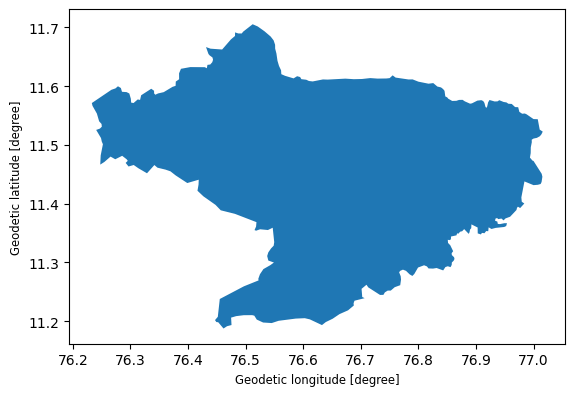

In [ ]:
nilgiris.plot()

In [ ]:
nilgiris

,DISTRICT,ST_NM,ST_CEN_CD,DT_CEN_CD,censuscode,geometry
564,The Nilgiris,Tamil Nadu,33,10,611,"POLYGON ((76.84683 11.58238, 76.85013 11.58075..."


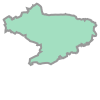

In [ ]:
nilgiris = nilgiris.reset_index(drop=True)
geom = nilgiris['geometry'][0] # You need a shapely geometry
geom


In [ ]:
catalog = Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=planetary_computer.sign_inplace,)

In [ ]:
collections = catalog.get_all_collections()

datasets = []
for col in collections:
    datasets.append({'collection': col.id, 'description': col.description})
df_col = pd.DataFrame(datasets)
## df_col # If you uncomment this, you can easily browse the table in Google Colab

In [ ]:
df_dem = df_col[df_col["collection"].str.contains("dem", case=False, na=False)]
df_dem

,collection,description
10,alos-dem,"The ""ALOS World 3D-30m"" (AW3D30) dataset is a ..."
22,cop-dem-glo-30,The Copernicus DEM is a digital surface model ...
23,cop-dem-glo-90,The Copernicus DEM is a digital surface model ...
96,nasadem,[NASADEM](https://earthdata.nasa.gov/esds/comp...


In [ ]:
df_era5 = df_col[df_col["collection"].str.contains("era5", case=False, na=False)]
df_era5

,collection,description
38,era5-pds,ERA5 is the fifth generation ECMWF atmospheric...


In [ ]:
items = catalog.search(
    collections=["cop-dem-glo-30"],
    intersects = geom
).item_collection()
len(items)

2

In [ ]:
items_df = gpd.GeoDataFrame.from_features(items.to_dict(), crs='EPSG:4326')
items_df


,geometry,gsd,datetime,platform,proj:shape,proj:transform,proj:code
0,"POLYGON ((77.99986 11.00014, 77.99986 12.00014...",30,2021-04-22T00:00:00Z,TanDEM-X,"[3600, 3600]","[0.0002777777777777778, 0.0, 76.99986111111112...",EPSG:4326
1,"POLYGON ((76.99986 11.00014, 76.99986 12.00014...",30,2021-04-22T00:00:00Z,TanDEM-X,"[3600, 3600]","[0.0002777777777777778, 0.0, 75.99986111111112...",EPSG:4326


In [ ]:
rasters = []

for item in items:
    href = item.assets["data"].href
    dem = rxr.open_rasterio(href)
    rasters.append(dem)

print("Loaded tiles:", len(rasters))

Loaded tiles: 2


In [ ]:
rasters

[<xarray.DataArray (band: 1, y: 3600, x: 3600)> Size: 52MB
 [12960000 values with dtype=float32]
 Coordinates:
   * band         (band) int64 8B 1
   * y            (y) float64 29kB 12.0 12.0 12.0 12.0 ... 11.0 11.0 11.0 11.0
   * x            (x) float64 29kB 77.0 77.0 77.0 77.0 ... 78.0 78.0 78.0 78.0
     spatial_ref  int64 8B 0
 Attributes:
     AREA_OR_POINT:  Point
     scale_factor:   1.0
     add_offset:     0.0,
 <xarray.DataArray (band: 1, y: 3600, x: 3600)> Size: 52MB
 [12960000 values with dtype=float32]
 Coordinates:
   * band         (band) int64 8B 1
   * y            (y) float64 29kB 12.0 12.0 12.0 12.0 ... 11.0 11.0 11.0 11.0
   * x            (x) float64 29kB 76.0 76.0 76.0 76.0 ... 77.0 77.0 77.0 77.0
     spatial_ref  int64 8B 0
 Attributes:
     AREA_OR_POINT:  Point
     scale_factor:   1.0
     add_offset:     0.0]

In [ ]:
merged_raster = merge_arrays(dataarrays = rasters)

In [ ]:
merged_raster

<xarray.DataArray (band: 1, y: 3600, x: 7200)> Size: 104MB
array([[[832.0585  , 834.6837  , 835.91516 , ..., 464.61276 ,
         462.9806  , 461.6544  ],
        [830.9763  , 835.4224  , 836.96155 , ..., 465.4454  ,
         463.342   , 461.7499  ],
        [832.12305 , 834.2067  , 833.8266  , ..., 465.64676 ,
         463.67758 , 462.30383 ],
        ...,
        [ 75.32815 ,  76.19822 ,  75.5008  , ..., 170.48672 ,
         171.18375 , 171.54716 ],
        [ 75.885284,  75.70687 ,  72.86259 , ..., 170.58372 ,
         171.33511 , 171.56807 ],
        [ 72.32363 ,  71.818405,  70.19609 , ..., 170.08302 ,
         170.08113 , 171.47972 ]]], dtype=float32)
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 29kB 12.0 12.0 12.0 12.0 ... 11.0 11.0 11.0 11.0
  * x            (x) float64 58kB 76.0 76.0 76.0 76.0 ... 78.0 78.0 78.0 78.0
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Point
    scale_factor:   1.0
    add_offset:     0.0

In [ ]:
merged_raster.values

array([[[832.0585  , 834.6837  , 835.91516 , ..., 464.61276 ,
         462.9806  , 461.6544  ],
        [830.9763  , 835.4224  , 836.96155 , ..., 465.4454  ,
         463.342   , 461.7499  ],
        [832.12305 , 834.2067  , 833.8266  , ..., 465.64676 ,
         463.67758 , 462.30383 ],
        ...,
        [ 75.32815 ,  76.19822 ,  75.5008  , ..., 170.48672 ,
         171.18375 , 171.54716 ],
        [ 75.885284,  75.70687 ,  72.86259 , ..., 170.58372 ,
         171.33511 , 171.56807 ],
        [ 72.32363 ,  71.818405,  70.19609 , ..., 170.08302 ,
         170.08113 , 171.47972 ]]], dtype=float32)

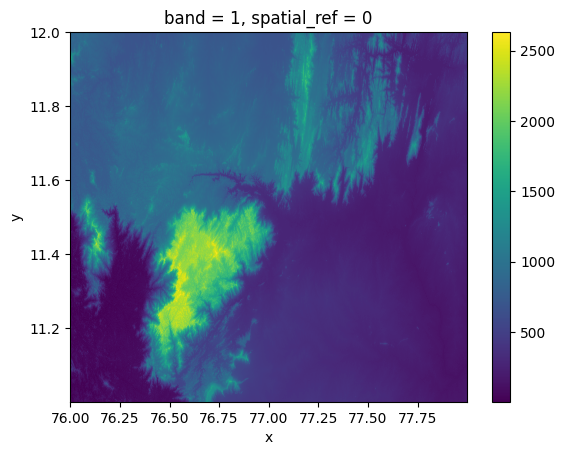

In [ ]:
merged_raster.plot()

In [ ]:
print(f'It is {str(nilgiris.crs.to_epsg()) == items[0].properties['proj:code'].split(":")[1]} that shape file of the Nilgiris and the digital elevation are the same.')

It is True that shape file of the Nilgiris and the digital elevation are the same.


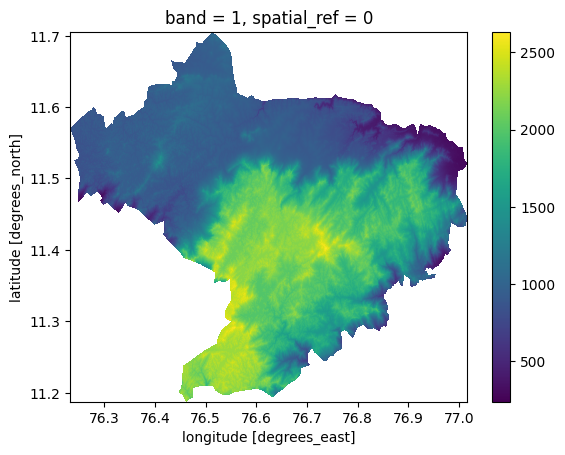

In [ ]:
dem_clipped = merged_raster.rio.clip(nilgiris['geometry'])
dem_clipped.plot()

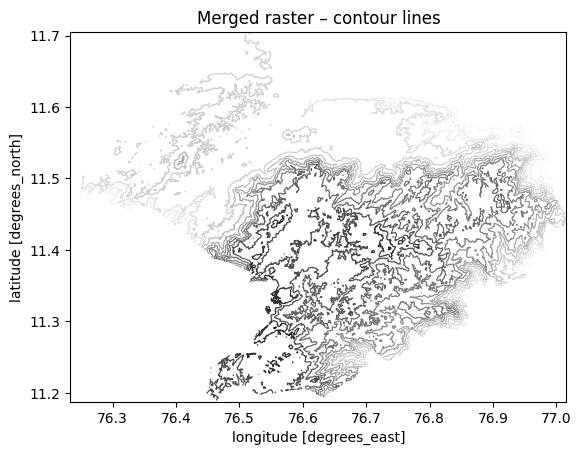

In [ ]:
fig, ax = plt.subplots()

dem_clipped.squeeze(dim="band").plot.contour(
    ax=ax,
    cmap="Greys",
    levels=15,
    linewidths=0.8
)

ax.set_title("Merged raster – contour lines")
ax.set_aspect("auto")

plt.show()

In [ ]:
import matplotlib.pyplot as plt

print(plt.colormaps())

['magma', 'inferno', 'plasma', 'viridis', 'cividis', 'twilight', 'twilight_shifted', 'turbo', 'berlin', 'managua', 'vanimo', 'Blues', 'BrBG', 'BuGn', 'BuPu', 'CMRmap', 'GnBu', 'Greens', 'Greys', 'OrRd', 'Oranges', 'PRGn', 'PiYG', 'PuBu', 'PuBuGn', 'PuOr', 'PuRd', 'Purples', 'RdBu', 'RdGy', 'RdPu', 'RdYlBu', 'RdYlGn', 'Reds', 'Spectral', 'Wistia', 'YlGn', 'YlGnBu', 'YlOrBr', 'YlOrRd', 'afmhot', 'autumn', 'binary', 'bone', 'brg', 'bwr', 'cool', 'coolwarm', 'copper', 'cubehelix', 'flag', 'gist_earth', 'gist_gray', 'gist_heat', 'gist_ncar', 'gist_rainbow', 'gist_stern', 'gist_yarg', 'gnuplot', 'gnuplot2', 'gray', 'hot', 'hsv', 'jet', 'nipy_spectral', 'ocean', 'pink', 'prism', 'rainbow', 'seismic', 'spring', 'summer', 'terrain', 'winter', 'Accent', 'Dark2', 'Paired', 'Pastel1', 'Pastel2', 'Set1', 'Set2', 'Set3', 'tab10', 'tab20', 'tab20b', 'tab20c', 'grey', 'gist_grey', 'gist_yerg', 'Grays', 'magma_r', 'inferno_r', 'plasma_r', 'viridis_r', 'cividis_r', 'twilight_r', 'twilight_shifted_r', 't

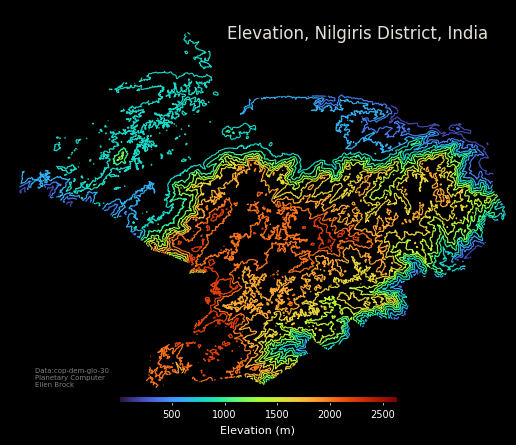

In [ ]:
fig, ax = plt.subplots()

fig.patch.set_facecolor("black")
ax.set_facecolor("black")

dem_clipped.squeeze(dim="band").plot.contour(
    ax=ax,
    cmap="turbo",
    levels=15,
    linewidths=0.8,
    ## add_colorbar=True
)
## Based on tutorial:
## https://matplotlib.org/stable/users/explain/colors/colorbar_only.html
vals = np.array(merged_raster.values)
norm = mpl.colors.Normalize(vmin=vals.min(), vmax=vals.max())
cmap = plt.cm.turbo
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

# Add very small, centered horizontal colorbar
cbar = fig.colorbar(
    sm,
    ax=ax,
    orientation='horizontal',
    ## https://casrai.org/guides/colorbar-in-matplotlib
    # fraction=0.015,   # thin bar
    # pad=0.02,         # tight spacing
    # aspect=50,         # long
    # shrink=0.65

    fraction=0.015,  # thinner
    pad=0.02,       # closer to map
    aspect=50,       # longer relative to its thickness
    shrink=0.65
)
cbar.set_label(
    'Elevation (m)',
    color='white',
    fontsize=8,
    labelpad=4
)
cbar.ax.xaxis.set_tick_params(color='white', size=2, width=0.5)
plt.setp(cbar.ax.get_xticklabels(), color='white', fontsize=7)

ax.text(
    0.7, 0.98,
    "Elevation, Nilgiris District, India",
    transform=ax.transAxes,
    fontsize=12,
    color="#E6E1D8",
    ## weight="bold",
    ha="center"
)

ax.text(
    0.05, 0.005,
    "Data:cop-dem-glo-30 \nPlanetary Computer \nEllen Brock",
    transform=ax.transAxes,
    fontsize=5,
    color="gray",
    # ha="left",
    # va="bottom"
)
ax.set_axis_off()
ax.set_aspect("auto")

plt.savefig("day_02_lines.png", dpi=300, bbox_inches='tight')

plt.show()

## References

[Mapping and Data Visualization with Python Course by Ujaval Gandhi www.spatialthoughts.com](https://courses.spatialthoughts.com/python-dataviz.html)
